# AgriSignal: exploring the data

Before building any model I want to know three things:

1. Does the satellite data behave the way crops should (wheat in winter, rice in the monsoon)?
2. How do wheat and paddy prices move, and how much of that is just the calendar?
3. Is there any sign that crop health or rainfall today relates to price changes 1 to 3 months later?

The data is the national monthly table from `src/build_national.py`: NDVI and rainfall averaged over the main wheat states (204 districts) and rice states (222 districts), weighted by each district's farmland, plus the all-India wholesale price index (WPI).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

COLORS = {"wheat": "#c28a00", "paddy": "#2a7f62"}
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

national = pd.read_csv(Path("..") / "data" / "processed" / "national_monthly.csv")
national["date"] = pd.to_datetime(national["month"])
national["calendar_month"] = national["date"].dt.month
national = national.sort_values(["crop", "date"]).reset_index(drop=True)
national.head()

,crop,month,ndvi,rainfall_mm,wpi,districts,date,calendar_month
0,paddy,2018-01,0.5079,4.8,89.37,222,2018-01-01,1
1,paddy,2018-02,0.5101,19.4,89.96,222,2018-02-01,2
2,paddy,2018-03,0.4182,6.9,90.68,222,2018-03-01,3
3,paddy,2018-04,0.3245,35.3,91.09,222,2018-04-01,4
4,paddy,2018-05,0.3146,49.0,91.63,222,2018-05-01,5


## 1. Seasonal cycle of crop health

Average NDVI for each calendar month over 2018 to 2026. Wheat is sown in November and harvested in April, so the wheat states should be green from December to February. Rice grows in the monsoon, so the rice states should peak around August and September.

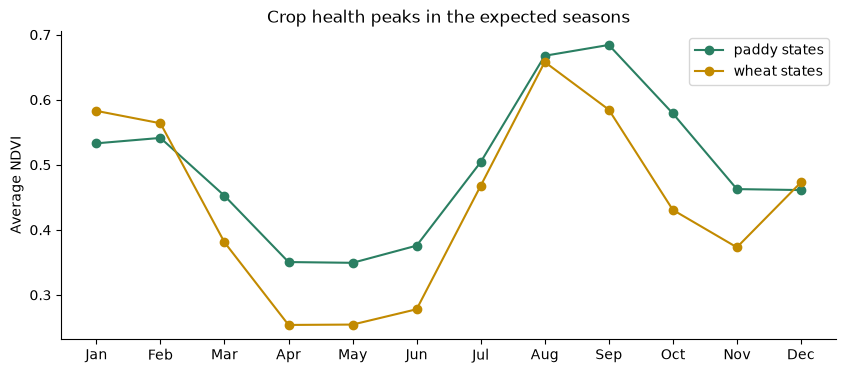

In [2]:
seasonal = national.groupby(["calendar_month", "crop"])["ndvi"].mean().unstack()

fig, ax = plt.subplots()
for crop in seasonal.columns:
    ax.plot(seasonal.index, seasonal[crop], marker="o", color=COLORS[crop], label=f"{crop} states")
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.set_ylabel("Average NDVI")
ax.set_title("Crop health peaks in the expected seasons")
ax.legend()
plt.show()

The wheat states also turn green in August. That is the kharif crop (rice, soybean, cotton) growing in the same states, not wheat, which is why the seasons have to be kept in mind later.

## 2. Crop health compared with normal

Because of the seasons, raw NDVI goes up and down every year no matter how good the harvest is. To see whether crops are doing better or worse than usual, I subtract the average for that calendar month (the anomaly). Above zero means greener than a normal year for that month.

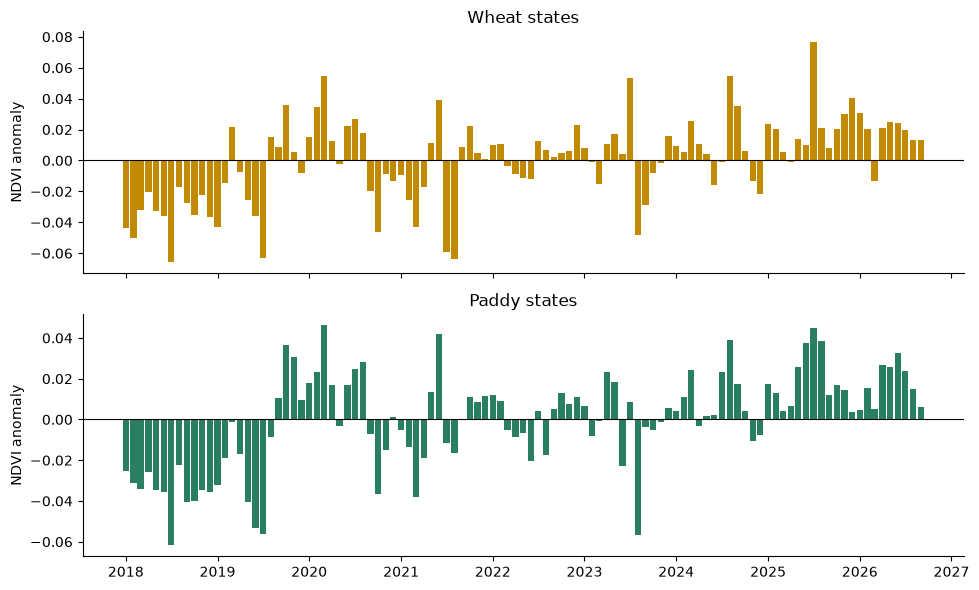

crop,paddy,wheat
date,,
2018,-0.035,-0.035
2019,-0.012,-0.009
2020,0.010,0.008
2021,-0.001,-0.011
2022,0.000,0.003
2023,-0.003,0.001
2024,0.009,0.008
2025,0.020,0.022
2026,0.017,0.017


In [3]:
for column in ["ndvi", "rainfall_mm"]:
    normal = national.groupby(["crop", "calendar_month"])[column].transform("mean")
    national[f"{column}_anomaly"] = national[column] - normal

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, crop in zip(axes, ["wheat", "paddy"]):
    data = national[national["crop"] == crop]
    ax.bar(data["date"], data["ndvi_anomaly"], width=25, color=COLORS[crop])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("NDVI anomaly")
    ax.set_title(f"{crop.title()} states")
plt.tight_layout()
plt.show()

yearly_anomaly = national.groupby([national["date"].dt.year, "crop"])["ndvi_anomaly"].mean().unstack()
yearly_anomaly.round(3)

## 3. Monsoon rainfall by year

Total June to September rainfall in the rice states, averaged over districts.

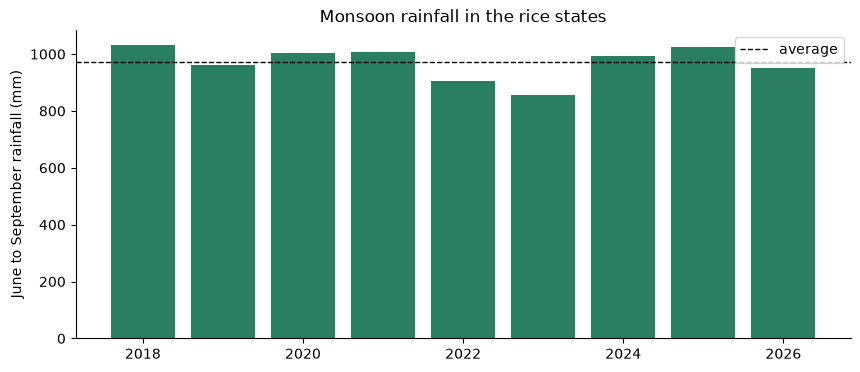

date
2018    1032.0
2019     962.0
2020    1004.0
2021    1009.0
2022     905.0
2023     858.0
2024     994.0
2025    1024.0
2026     950.0
Name: rainfall_mm, dtype: float64

In [4]:
paddy = national[national["crop"] == "paddy"]
monsoon = paddy[paddy["calendar_month"].between(6, 9)]
monsoon_total = monsoon.groupby(monsoon["date"].dt.year)["rainfall_mm"].sum()

fig, ax = plt.subplots()
ax.bar(monsoon_total.index, monsoon_total, color=COLORS["paddy"])
ax.axhline(monsoon_total.mean(), color="black", linestyle="--", linewidth=1, label="average")
ax.set_ylabel("June to September rainfall (mm)")
ax.set_title("Monsoon rainfall in the rice states")
ax.legend()
plt.show()
monsoon_total.round(0)

## 4. Prices

The WPI is an index, not rupees per quintal, but its ups and downs follow wholesale prices. The dotted line marks April 2023, where the data switches from the old (2011-12) series to the new (2022-23) one.

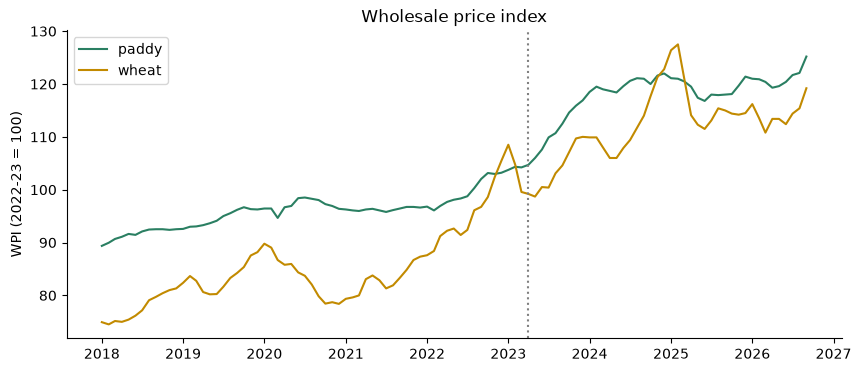

crop,paddy,wheat
date,,
2018,NaN,NaN
2019,3.4,7.6
2020,2.6,0.3
2021,-0.8,-0.9
2022,3.4,14.2
2023,9.8,9.8
2024,9.8,7.9
2025,-0.7,4.1
2026,1.7,-2.0


In [5]:
fig, ax = plt.subplots()
for crop, data in national.groupby("crop"):
    ax.plot(data["date"], data["wpi"], color=COLORS[crop], label=crop)
ax.axvline(pd.Timestamp("2023-04-01"), color="grey", linestyle=":")
ax.set_ylabel("WPI (2022-23 = 100)")
ax.set_title("Wholesale price index")
ax.legend()
plt.show()

yearly_change = national.groupby([national["date"].dt.year, "crop"])["wpi"].mean().unstack().pct_change() * 100
yearly_change.round(1)

## 5. How much of the up and down is just the calendar?

This matters for the model: if prices almost always rise in some months and fall in others, a model that only knows the month can already look accurate. Any satellite model has to beat that.

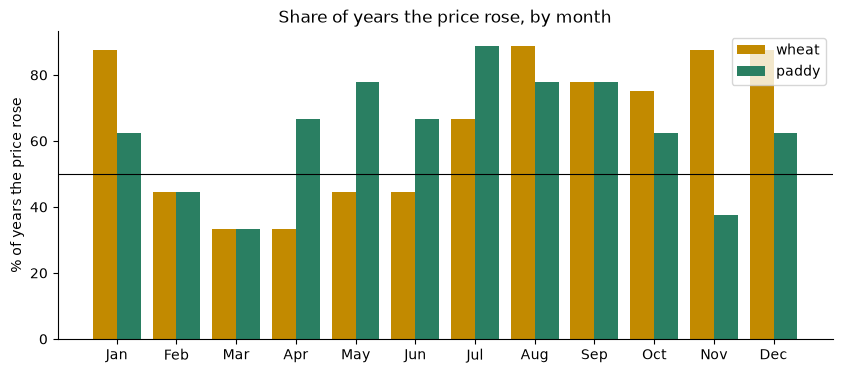

crop
paddy    0.63
wheat    0.63
Name: price_change, dtype: float64

In [6]:
national["price_change"] = national.groupby("crop")["wpi"].pct_change() * 100
share_up = (
    national.dropna(subset=["price_change"])
    .assign(went_up=lambda df: df["price_change"] > 0)
    .groupby(["calendar_month", "crop"])["went_up"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots()
width = 0.4
for offset, crop in zip([-width / 2, width / 2], ["wheat", "paddy"]):
    ax.bar(share_up.index + offset, share_up[crop] * 100, width, color=COLORS[crop], label=crop)
ax.axhline(50, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.set_ylabel("% of years the price rose")
ax.set_title("Share of years the price rose, by month")
ax.legend()
plt.show()

overall_up = national.dropna(subset=["price_change"]).groupby("crop")["price_change"].apply(lambda s: (s > 0).mean())
overall_up.round(2)

## 6. Does crop health or rainfall relate to later price changes?

For each month I take the NDVI and rainfall anomalies and compare them with the price change over the next 1, 2 and 3 months. If good crops push prices down, the correlation should be negative. With about 100 months, a correlation needs to be bigger than roughly 0.2 (either sign) before it is unlikely to be chance.

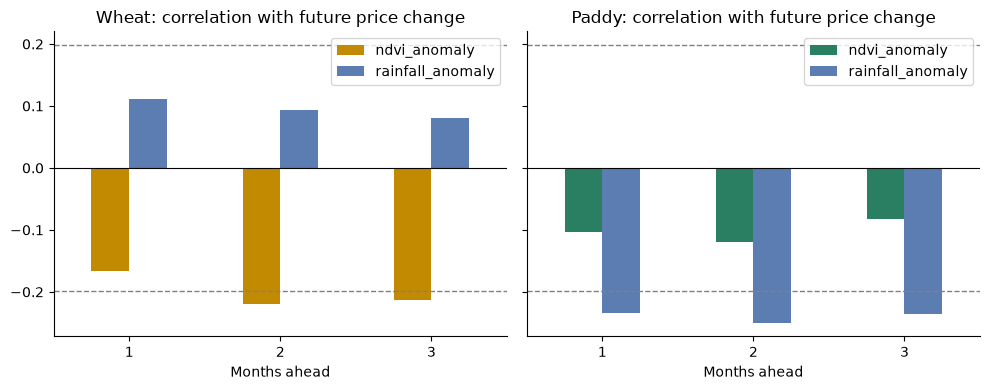

,crop,months_ahead,ndvi_anomaly,rainfall_anomaly,months_used
0,paddy,1,-0.104,-0.234,104
1,paddy,2,-0.120,-0.250,103
2,paddy,3,-0.082,-0.235,102
3,wheat,1,-0.166,0.111,104
4,wheat,2,-0.219,0.094,103
5,wheat,3,-0.213,0.081,102


In [7]:
rows = []
for crop, data in national.groupby("crop"):
    for months_ahead in [1, 2, 3]:
        future_change = (data["wpi"].shift(-months_ahead) / data["wpi"] - 1) * 100
        rows.append(
            {
                "crop": crop,
                "months_ahead": months_ahead,
                "ndvi_anomaly": data["ndvi_anomaly"].corr(future_change),
                "rainfall_anomaly": data["rainfall_mm_anomaly"].corr(future_change),
                "months_used": future_change.notna().sum(),
            }
        )
lag_corr = pd.DataFrame(rows)
threshold = 2 / lag_corr["months_used"].min() ** 0.5

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, crop in zip(axes, ["wheat", "paddy"]):
    data = lag_corr[lag_corr["crop"] == crop].set_index("months_ahead")
    data[["ndvi_anomaly", "rainfall_anomaly"]].plot.bar(ax=ax, color=[COLORS[crop], "#5b7db1"], rot=0)
    for line in [threshold, -threshold]:
        ax.axhline(line, color="grey", linestyle="--", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{crop.title()}: correlation with future price change")
    ax.set_xlabel("Months ahead")
plt.tight_layout()
plt.show()
lag_corr.round(3)

## 7. Case study: the 2022 heatwave

In March 2022 an early heatwave hit north India just before the wheat harvest, wheat prices rose sharply and the government banned wheat exports in May. Did the satellite data see it?

In [8]:
wheat = national[national["crop"] == "wheat"].set_index("month")
wheat.loc["2021-12":"2022-07", ["ndvi", "ndvi_anomaly", "wpi", "price_change"]].round(3)

,ndvi,ndvi_anomaly,wpi,price_change
month,,,,
2021-12,0.474,0.001,87.33,0.738
2022-01,0.593,0.010,87.60,0.309
2022-02,0.574,0.011,88.40,0.913
2022-03,0.377,-0.004,91.22,3.190
2022-04,0.245,-0.009,92.23,1.107
2022-05,0.243,-0.011,92.65,0.455
2022-06,0.266,-0.012,91.43,-1.317
2022-07,0.480,0.012,92.39,1.050


## 8. Checking the greening trend

The anomaly chart in section 2 drifts upward: 2018 and 2019 are mostly below normal and 2025 and 2026 mostly above. That could be better farming, a wetter run of years, or slow drift in the satellites. A trend like that can create or hide a correlation, so I remove a straight-line trend from the NDVI anomaly and also remove the usual calendar-month price change, then repeat section 6.

In [9]:
import numpy as np

rows = []
for crop, data in national.groupby("crop"):
    step = np.arange(len(data))
    slope, intercept = np.polyfit(step, data["ndvi_anomaly"], 1)
    detrended = data["ndvi_anomaly"] - (slope * step + intercept)
    for months_ahead in [1, 2, 3]:
        future_change = (data["wpi"].shift(-months_ahead) / data["wpi"] - 1) * 100
        usual_change = future_change.groupby(data["calendar_month"]).transform("mean")
        unusual_change = future_change - usual_change
        rows.append(
            {
                "crop": crop,
                "months_ahead": months_ahead,
                "ndvi_trend_per_year": slope * 12,
                "ndvi_anomaly": detrended.corr(unusual_change),
                "rainfall_anomaly": data["rainfall_mm_anomaly"].corr(unusual_change),
            }
        )
pd.DataFrame(rows).round(3)

,crop,months_ahead,ndvi_trend_per_year,ndvi_anomaly,rainfall_anomaly
0,paddy,1,0.005,-0.162,-0.249
1,paddy,2,0.005,-0.178,-0.265
2,paddy,3,0.005,-0.134,-0.252
3,wheat,1,0.005,-0.204,0.124
4,wheat,2,0.005,-0.264,0.099
5,wheat,3,0.005,-0.252,0.076


## What I found

**The satellite data behaves like real crops.** Wheat states are greenest in January and February and turn brown at the April harvest. Rice states peak in August and September. The 2023 monsoon was the weakest in the data (858 mm against about 970 mm on average), which matches 2023 being an El Nino year.

**The calendar alone explains a lot of the up and down.** Prices rose in 63% of months for both crops. Wheat usually falls from February to June, when the new harvest arrives, and rises from July to January. Any model has to beat a simple "guess from the month" baseline, not just "always up".

**There is a weak signal in the expected direction.**
- When the wheat states are greener than normal, wheat prices tend to rise less over the next 2 to 3 months (correlation about -0.22, and about -0.25 once the trend and calendar effects are removed).
- For paddy, rainfall is the clearer signal: a wetter month than normal goes with smaller paddy price rises over the next 1 to 3 months (about -0.25). Paddy NDVI is weaker (about -0.17 after removing the trend).
- Rainfall does not help for wheat (about +0.1). That makes sense, since most wheat is irrigated.

**Caveats.**
- These are small correlations from about 100 months. For 2 and 3 months ahead the windows overlap, so neighbouring months are not independent and the real evidence is weaker than the 0.2 line suggests. The next phase tests this properly.
- NDVI has an upward trend of about 0.005 per year. Removing it made the signals slightly stronger, not weaker, so the trend is not creating them.
- The 2022 heatwave barely shows in monthly NDVI (March 2022 was only 0.004 below normal), even though wheat prices jumped 3.2% that month. Heat mostly shrank the grain, not the green leaves, so NDVI cannot see every kind of crop damage.
- The anomalies here use averages from the whole period, which is fine for exploring. In the model they must only use past data, or the model would be using information from the future.
- 2026 only has January to September.

**Next:** Granger causality tests to check whether NDVI and rainfall add information about future prices beyond past prices and the calendar, and then a model that has to beat the calendar baseline.
